# 04 Topic modeling: คำทำนายพูดถึงเรื่องอะไร

**เจ้าของ:** Member 5 · **ข้อมูล:** `data/processed/horoscopes.csv`

**คำถาม (วัตถุประสงค์ข้อ 2):** หัวข้อหลักที่ดวงพูดถึงคืออะไร (การงาน การเงิน ความรัก สุขภาพ โชคลาภ ฯลฯ)
และสัดส่วนของหัวข้อต่างกันตามเว็บหรือตามราศี

**วิธี (L10 Topic modeling):** LSA และ LDA ด้วย gensim เลือกจำนวน topic (k) ด้วย **coherence score (c_v)**
- **ส่วน A: ทุกข้อความรวมกัน** (ตามแผนเดิม) → topic ที่ได้สะท้อน**เนื้อหา** หรือสะท้อน**คนเขียน**
- **ส่วน B: ทำ LDA แยกในแต่ละเว็บ** → ตัดผลของคนเขียนออก เพื่อดูหัวข้อเนื้อหาจริง และดูว่าสัดส่วนหัวข้อต่างกันตามราศีไหม

ทำไมต้องมีส่วน B: ตอนทดลองพบว่า LDA บนทุกข้อความได้ topic ที่**แต่ละ topic เป็นของเว็บเดียว** (ส่วน A แสดงผลนี้)
แม้จะลองเก็บเฉพาะคำที่ใช้ร่วมกันหลายเว็บแล้ว topic ก็ยังแยกตามเว็บ จึงต้องทำ topic model ภายในเว็บเดียวกันเพื่อดูหัวข้อเนื้อหา

- **ส่วน C: BERTopic** (embedding → UMAP → HDBSCAN → c-TF-IDF) ใช้ความหมายแทนการนับคำ เพื่อดูว่าได้ข้อสรุปเดียวกันไหม

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel, LsiModel, TfidfModel
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency

warnings.filterwarnings("ignore", category=DeprecationWarning)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.thai_text import THAI_FONT, ZODIAC_TH, clean_text, tokenize

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
CACHE_DIR = PROJECT_ROOT / "outputs"          # coherence results are saved here (slow to compute)
RECOMPUTE = False                              # True = compute coherence again even if a saved file exists
font_manager.fontManager.addfont(THAI_FONT)
THAI_FONT_NAME = font_manager.FontProperties(fname=THAI_FONT).get_name()
plt.rcParams.update({
    "font.family": THAI_FONT_NAME, "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "normal",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
SITES = ["marumura", "sanook", "thairath", "kapook"]
SIGNS = ["Aries", "Taurus", "Gemini", "Cancer", "Leo", "Virgo", "Libra", "Scorpio",
         "Sagittarius", "Capricorn", "Aquarius", "Pisces"]
SIGN_TH = {en: th for th, en in ZODIAC_TH.items()}
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

## 1) เตรียมข้อความสำหรับ topic model

นอกจาก `clean_text` + `tokenize` (ลบชื่อราศี ตัดคำ ตัด stopword) ยังตัดคำต่อไปนี้ออก**เฉพาะในโน้ตบุ๊กนี้**:
- **หัวข้อประจำของ kapook** เช่น "เรื่องสำคัญของคุณในสัปดาห์นี้", "สถานการณ์การเงิน" เพราะโผล่ในทุกข้อความของ kapook และไม่ใช่เนื้อหา
- **คำหัวข้อ** "การงาน", "การเงิน", "ความรัก", "สุขภาพ", "คำแนะนำ" ที่เว็บใช้เป็นชื่อหัวข้อ (ถ้าเก็บไว้ topic จะจับตามโครงสร้างหัวข้อของแต่ละเว็บ)
- **คำทั่วไป** "ที่จะ", "วันที่", "ทำ", "เรื่อง" (เหมือนใน 01_eda)

topic จะต้องถูกระบุจากคำเนื้อหา เช่น "เงิน", "รายได้", "คู่", "งาน" แทน

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "horoscopes.csv")
KAPOOK_HEADERS = ["เรื่องสำคัญของคุณในสัปดาห์นี้", "ความรัก ความสัมพันธ์", "สถานการณ์การเงิน",
                  "ธุรกิจ การงาน", "คำเตือนหรือปัญหาที่อาจเกิดขึ้น", "คำแนะนำพิเศษ"]
TOPIC_STOPWORDS = {"ที่จะ", "วันที่", "ทำ", "เรื่อง", "การงาน", "การเงิน", "ความรัก", "สุขภาพ", "คำแนะนำ"}

def topic_tokens(text):
    for header in KAPOOK_HEADERS:
        text = text.replace(header, " ")
    return [w for w in tokenize(clean_text(text)) if w not in TOPIC_STOPWORDS]

df["tokens"] = df["text"].apply(topic_tokens)
print(df.shape, "| mean tokens per text:", round(df["tokens"].str.len().mean(), 1))

(1233, 11) | mean tokens per text: 68.1


In [3]:
def build_corpus(token_lists, no_below=5, no_above=0.5):
    """gensim dictionary + bag-of-words. Drop words in < no_below texts or > no_above share of texts."""
    dictionary = Dictionary(token_lists)
    dictionary.filter_extremes(no_below=no_below, no_above=no_above)
    return dictionary, [dictionary.doc2bow(t) for t in token_lists]

def fit_lda(corpus, dictionary, k):
    return LdaModel(corpus, num_topics=k, id2word=dictionary, passes=10, iterations=200, random_state=42)

def fit_lsa(corpus, dictionary, k):
    tfidf = TfidfModel(corpus)
    return LsiModel(tfidf[corpus], num_topics=k, id2word=dictionary, random_seed=42)

def lsa_top_words(lsa, k, n=10):
    """LSA topics have + and - weights; we show the words with the largest positive weight."""
    return [[w for w, wt in sorted(lsa.show_topic(t, 50), key=lambda x: -x[1])[:n]] for t in range(k)]

def coherence(topics_words, token_lists, dictionary):
    return CoherenceModel(topics=topics_words, texts=token_lists, dictionary=dictionary,
                          coherence="c_v", processes=1).get_coherence()

def doc_topic_matrix(lda, corpus, k):
    """theta[i, t] = share of topic t in text i."""
    theta = np.zeros((len(corpus), k))
    for i, bow in enumerate(corpus):
        for t, p in lda.get_document_topics(bow, minimum_probability=0):
            theta[i, t] = p
    return theta

def topic_labels(lda, k, n=4):
    return [f"T{t + 1}: " + " ".join(w for w, _ in lda.show_topic(t, n)) for t in range(k)]

## ส่วน A: LSA vs LDA บนทุกข้อความ

ลอง k = 2 ถึง 12 และคำนวณ c_v coherence ของทั้ง 2 วิธี (ค่าสูง = คำใน topic เดียวกันมักอยู่ด้วยกันจริง ตีความง่าย)
ใช้ k ที่ coherence ของ LDA สูงสุดในช่วง 3–12 (k = 2 หยาบเกินไปที่จะตั้งชื่อหัวข้อ) ใช้เวลาประมาณ 13 นาทีในครั้งแรก จากนั้นผลจะถูกบันทึกไว้ที่ `outputs/04_coherence_all.csv` และครั้งต่อไปจะโหลดจากไฟล์

In [4]:
dictionary_all, corpus_all = build_corpus(df["tokens"].tolist())
print("vocabulary:", len(dictionary_all), "words")

cache = CACHE_DIR / "04_coherence_all.csv"
if cache.exists() and not RECOMPUTE:
    coh_all = pd.read_csv(cache)
else:
    rows = []
    for k in range(2, 13):
        lda = fit_lda(corpus_all, dictionary_all, k)
        lda_words = [[w for w, _ in lda.show_topic(t, 10)] for t in range(k)]
        lsa = fit_lsa(corpus_all, dictionary_all, k)
        rows.append({"k": k,
                     "LDA": coherence(lda_words, df["tokens"].tolist(), dictionary_all),
                     "LSA": coherence(lsa_top_words(lsa, k), df["tokens"].tolist(), dictionary_all)})
        print("k =", k, "done")
    coh_all = pd.DataFrame(rows)
    coh_all.to_csv(cache, index=False)
coh_all.round(3).set_index("k").T

vocabulary: 2164 words


k,2,3,4,5,6,7,8,9,10,11,12
LDA,0.488,0.484,0.437,0.432,0.456,0.434,0.455,0.472,0.462,0.467,0.474
LSA,0.600,0.650,0.535,0.651,0.619,0.597,0.524,0.660,0.525,0.682,0.523


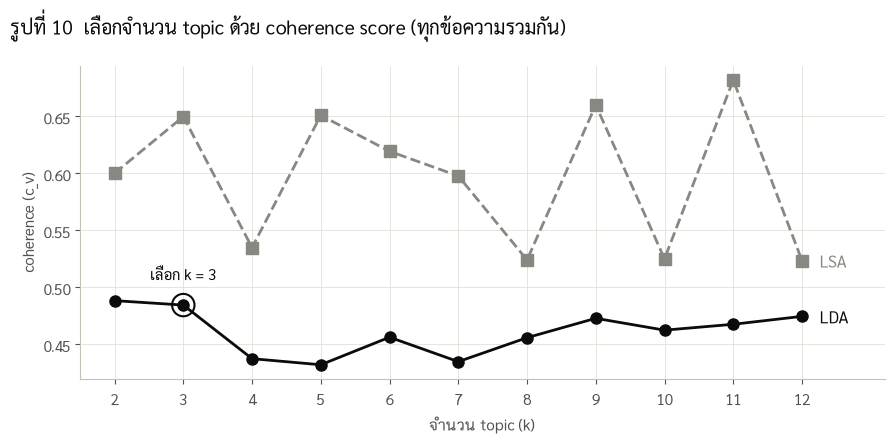

In [5]:
# Figure 10: coherence vs number of topics
# choose k in 3..12 (k = 2 is too coarse to name topics; same rule as part B)
K_ALL = int(coh_all.loc[coh_all.loc[coh_all["k"] >= 3, "LDA"].idxmax(), "k"])
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, color, style, marker in [("LDA", "#0b0b0b", "-", "o"), ("LSA", "#898781", "--", "s")]:
    ax.plot(coh_all["k"], coh_all[name], color=color, linestyle=style, marker=marker, markersize=8, linewidth=2)
    ax.text(coh_all["k"].iloc[-1] + 0.25, coh_all[name].iloc[-1], name, va="center", fontsize=12, color=color)
ax.scatter([K_ALL], [coh_all.set_index("k").loc[K_ALL, "LDA"]], s=260, facecolors="none", edgecolors="#0b0b0b", linewidths=1.5)
ax.annotate(f"เลือก k = {K_ALL}", (K_ALL, coh_all.set_index("k").loc[K_ALL, "LDA"]), xytext=(0, 18), textcoords="offset points",
            ha="center", fontsize=11)
ax.set_xticks(coh_all["k"])
ax.set_xlabel("จำนวน topic (k)")
ax.set_ylabel("coherence (c_v)")
ax.set_xlim(1.5, 13.2)
fig.suptitle("รูปที่ 10  เลือกจำนวน topic ด้วย coherence score (ทุกข้อความรวมกัน)", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_coherence_all.png")
plt.show()

**จากรูปที่ 10 พบว่า**
- **LDA:** coherence ค่อนข้างแบน (0.43–0.49) จึงไม่มีจำนวน topic ที่ดีกว่าอย่างชัดเจน ค่าสูงสุดในช่วง 3–12 คือ **k = 3** (0.484) จึงใช้ k = 3
- **LSA:** coherence สูงกว่า LDA (0.52–0.68) แต่**ขึ้นลงสลับกันแทบทุก k** ทำให้เลือก k จาก LSA ได้ยาก
  ค่า c_v ของ LSA ไม่ได้แปลว่า topic ตีความง่ายกว่า เพราะ topic ของ LSA มีทั้งน้ำหนักบวกและลบ เราใช้เฉพาะคำที่มีน้ำหนักบวกมาคำนวณ

coherence ที่แบนเป็นสัญญาณแรกว่าข้อความไม่ได้แบ่งเป็นหัวข้อเนื้อหาที่ชัดเจน

In [6]:
# Top words: LDA (k with the best LDA coherence) and LSA (same k, for comparison)
lda_all = fit_lda(corpus_all, dictionary_all, K_ALL)
lsa_all = fit_lsa(corpus_all, dictionary_all, K_ALL)
pd.DataFrame({
    "LDA top 10": [" ".join(w for w, _ in lda_all.show_topic(t, 10)) for t in range(K_ALL)],
    "LSA top 10": [" ".join(ws) for ws in lsa_top_words(lsa_all, K_ALL)],
}, index=[f"T{t + 1}" for t in range(K_ALL)])

,LDA top 10,LSA top 10
T1,ควรระวัง ดาว อยู่ในเกณฑ์ รัก เขต เป็นพิเศษ สัญ...,ควรระวัง อยู่ในเกณฑ์ ดาว เป็นพิเศษ รัก เขต มาก...
T2,อย่า คู่ งาน มีโอกาส เข้ามา เงิน เจอ มีปัญหา ด...,มีเรื่อง คู่ มีปัญหา ดวง ความสัมพันธ์ ปัญหา เห...
T3,ตัวเอง มีเรื่อง ระวัง ปัญหา งาน สถานการณ์ ความ...,ทำบุญ เสริม ไก่ หมอ ดวง คู่ แนะนำ มีโอกาส ประส...


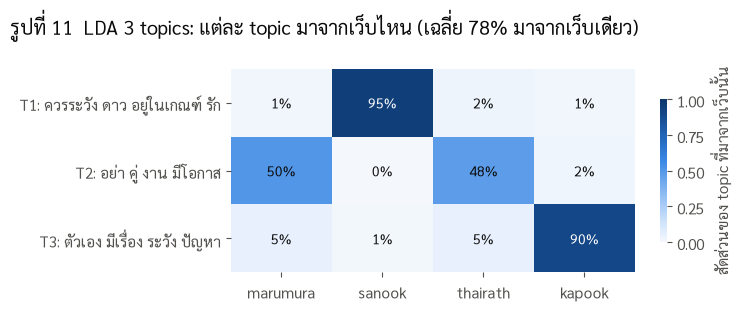

topic purity = 0.78  (1.0 = every topic from one site only, 0.25 = spread evenly)


In [7]:
# Figure 11: where does each LDA topic come from? (share of the topic per site)
theta_all = doc_topic_matrix(lda_all, corpus_all, K_ALL)
by_site = pd.DataFrame(theta_all, columns=topic_labels(lda_all, K_ALL)).groupby(df["source"]).sum().reindex(SITES)
from_site = by_site / by_site.sum()                       # columns sum to 1: "this topic comes X% from site S"
purity = from_site.max().mean()

fig, ax = plt.subplots(figsize=(7.5, 0.55 * K_ALL + 1.5))
im = ax.imshow(from_site.T.values, cmap=BLUE_RAMP, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(SITES)), SITES)
ax.set_yticks(range(K_ALL), from_site.columns)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(K_ALL):
    for j in range(len(SITES)):
        v = from_site.T.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=10, color="white" if v > 0.55 else "#0b0b0b")
cbar = fig.colorbar(im, ax=ax, shrink=0.7)
cbar.set_label("สัดส่วนของ topic ที่มาจากเว็บนั้น")
cbar.outline.set_visible(False)
fig.suptitle(f"รูปที่ 11  LDA {K_ALL} topics: แต่ละ topic มาจากเว็บไหน (เฉลี่ย {purity:.0%} มาจากเว็บเดียว)",
             x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_topics_by_site_all.png")
plt.show()
print(f"topic purity = {purity:.2f}  (1.0 = every topic from one site only, 0.25 = spread evenly)")

**จากตาราง top words และรูปที่ 11 พบว่า** topic ของ LDA บนทุกข้อความ**แทบเป็นชื่อเว็บ**
- **T1** (ควรระวัง ดาว อยู่ในเกณฑ์ เขต …) มาจาก **sanook 95%**: เป็นภาษาโหราศาสตร์ของ sanook
- **T3** (ตัวเอง มีเรื่อง ระวัง ปัญหา สถานการณ์ …) มาจาก **kapook 90%**
- **T2** (อย่า คู่ งาน มีโอกาส เข้ามา เงิน …) เป็นของ **marumura 50% + thairath 48%** สองเว็บที่เขียนสั้นและใช้ภาษาง่ายคล้ายกัน
- โดยเฉลี่ย **78%** ของแต่ละ topic มาจากเว็บเดียว (ถ้าไม่เกี่ยวกับเว็บเลยควรได้ประมาณ 25%)

LSA ได้ผลแบบเดียวกัน เช่น LSA T3 "ทำบุญ เสริม ไก่ หมอ ดวง" คือคำแนะนำของ**หมอไก่** (thairath)

**ความหมาย:** topic model ที่ไม่มีใครบอกว่าข้อความไหนมาจากเว็บไหน ยังแยกข้อความตาม**ผู้เขียน** ไม่ได้แยกตามหัวข้อเนื้อหา และไม่ได้แยกตามราศี
ผลนี้ตรงกับโน้ตบุ๊ก 02 และ 03 ส่วน B จึงทำ topic model ภายในแต่ละเว็บเพื่อดูหัวข้อเนื้อหา

## ส่วน B: LDA ภายในแต่ละเว็บ

ทำ LDA แยกทีละเว็บ (ผู้เขียนคนเดียวกัน) แล้วเลือก k ด้วย c_v coherence ในช่วง **3–8**
(ไม่เลือก k = 2 เพราะหยาบเกินไปที่จะบอกหัวข้อ และเกิน 8 จะมีข้อมูลน้อยต่อ topic เพราะแต่ละเว็บมีแค่ประมาณ 300 ข้อความ)
ผลจะถูกบันทึกไว้ที่ `outputs/04_coherence_by_site.csv`

In [8]:
site_models = {}
cache = CACHE_DIR / "04_coherence_by_site.csv"
coh_site = pd.read_csv(cache) if cache.exists() and not RECOMPUTE else None
rows = []
for site in SITES:
    sub = df[df["source"] == site].reset_index(drop=True)
    dictionary, corpus = build_corpus(sub["tokens"].tolist(), no_below=3, no_above=0.5)
    if coh_site is None:
        for k in range(3, 9):
            lda = fit_lda(corpus, dictionary, k)
            words = [[w for w, _ in lda.show_topic(t, 10)] for t in range(k)]
            rows.append({"site": site, "k": k, "LDA": coherence(words, sub["tokens"].tolist(), dictionary)})
        print(site, "done")
    site_models[site] = {"data": sub, "dictionary": dictionary, "corpus": corpus}
if coh_site is None:
    coh_site = pd.DataFrame(rows)
    coh_site.to_csv(cache, index=False)
best_k = coh_site.loc[coh_site.groupby("site")["LDA"].idxmax()].set_index("site")["k"].reindex(SITES)
display(coh_site.pivot(index="site", columns="k", values="LDA").reindex(SITES).round(3))
print("chosen k per site:", best_k.to_dict())

k,3,4,5,6,7,8
site,,,,,,
marumura,0.395,0.414,0.361,0.385,0.395,0.347
sanook,0.428,0.493,0.529,0.515,0.515,0.533
thairath,0.360,0.361,0.380,0.365,0.357,0.360
kapook,0.288,0.293,0.293,0.295,0.299,0.297


chosen k per site: {'marumura': 4, 'sanook': 8, 'thairath': 5, 'kapook': 7}


In [9]:
# Fit the final LDA per site, list topics with top words and their overall share in that site
topic_rows = []
for site in SITES:
    m = site_models[site]
    k = int(best_k[site])
    m["lda"] = fit_lda(m["corpus"], m["dictionary"], k)
    m["theta"] = doc_topic_matrix(m["lda"], m["corpus"], k)
    m["labels"] = topic_labels(m["lda"], k)
    for t in range(k):
        topic_rows.append({"site": site, "topic": f"T{t + 1}", "share": m["theta"][:, t].mean(),
                           "top 10 words": " ".join(w for w, _ in m["lda"].show_topic(t, 10))})
topics_by_site = pd.DataFrame(topic_rows)
pd.set_option("display.max_colwidth", 200)
topics_by_site.round(3)

,site,topic,share,top 10 words
0,marumura,T1,0.298,เจอ เอาเป็นว่า เงิน ดู เวลา ไม่ต้อง รอ มีเรื่อง จ่าย ระวัง
1,marumura,T2,0.393,จ่าย รู้ งาน ไม่ต้อง รอ ระวัง คนอื่น เดินทาง เหมือน เหนื่อย
2,marumura,T3,0.172,เดิม กลับมา เจอ รอ ดีกว่า เดี๋ยว โอกาส เอาเป็นว่า มีปัญหา เหมือนเดิม
3,marumura,T4,0.137,รอ ซื้อ เพื่อน ระวัง แล้วก็ จบ เวลา หาย เข้ามา มีโชค
4,sanook,T1,0.095,อารมณ์ ดาวพฤหัสบดี เงินเดือน ติดต่อ มีโอกาส มนุษย์ เงิน ดาวเสาร์ บ้าน ผู้ใหญ่
5,sanook,T2,0.103,ดาวเสาร์ ปี มหาศาล เจ้า ชะตากรรม ราหู อารมณ์ เกิดขึ้น ดับ เงิน
6,sanook,T3,0.151,ดาวเสาร์ ชะตากรรม สร้าง ให้ได้ โชค ปล่อย ตัวเอง ดาวพฤหัสบดี ความทุกข์ ร่วมกับ
7,sanook,T4,0.106,เตรียมพร้อม เกิดขึ้น น้อยที่สุด ให้ได้ เสี่ยง กำเนิด ปี ผลประโยชน์ เป็นระยะ ระมัดระวัง
8,sanook,T5,0.329,มิตรสหาย ติดต่อ โอกาส เก็งกำไร เงิน เข้ามา คนโสด ให้ได้ เสี่ยงโชค ทะเลาะวิวาท
9,sanook,T6,0.041,ดาวอังคาร ระวัง มากเกินไป การศึกษา เดินหน้า หักโหม พลัง เจริญรุ่งเรือง ติดต่อ โครงการ


**จากตาราง topic ภายในแต่ละเว็บ** (ตั้งชื่อจาก top words)

| เว็บ (k) | หัวข้อที่พบ |
|---|---|
| **marumura** (4) | T1 เงิน/การใช้จ่าย (เงิน จ่าย) · T2 งานและการเดินทาง (งาน เดินทาง เหนื่อย) · T3 **สิ่งเก่ากลับมา** (เดิม กลับมา เหมือนเดิม) · T4 ซื้อของ/เพื่อน/โชค (ซื้อ เพื่อน มีโชค) |
| **sanook** (8) | topic ส่วนใหญ่เป็น**ดาว** เช่น T2/T3 ดาวเสาร์–ราหู–ชะตากรรม · T1/T8 ดาวพฤหัสบดี · T6 ดาวอังคาร · T7 ดาวอาทิตย์ ("อาทิตย์ ขุม จักรวาล") และมี **T5 (33%)** เป็นคำทำนายทั่วไป: เพื่อน เก็งกำไร เงิน คนโสด เสี่ยงโชค |
| **thairath** (5) | ทุก topic คล้ายกันมาก: "มีโอกาส ดี งาน เข้ามา รายได้" (โชคลาภ, รายได้, ความสำเร็จ) ส่วน **T4** มี "ทำบุญ แนะนำ เสริม หมอไก่" คือคำแนะนำให้ทำบุญเสริมดวง |
| **kapook** (7) | ทั้ง 7 topic ใช้คำชุดเดียวกัน (ความสัมพันธ์ สถานการณ์ งาน มีปัญหา ใจ ชีวิต) จึงแยกไม่ออก และ coherence ต่ำที่สุด (≈ 0.30) |

**ตอบวัตถุประสงค์ข้อ 2:** หัวข้อที่พบในทุกเว็บคือ **งาน เงิน ความสัมพันธ์ และโอกาส/ปัญหา** ซึ่งมาปนกันใน**ทุกข้อความ** เพราะทุกเว็บเขียนตามแม่แบบที่ทำนายครบทุกด้านในข้อความเดียว topic model จึงแยกเป็น topic "งาน" หรือ "ความรัก" ไม่ได้
สิ่งที่ทำให้ topic ต่างกันจริงคือ**จุดเน้นของแต่ละเว็บ**: sanook เน้นดาว, thairath เน้นโชคลาภและการทำบุญ, marumura เน้นเรื่องใช้เงินและสิ่งเก่าที่กลับมา, kapook เน้นปัญหาและความสัมพันธ์
ส่วน **สุขภาพ** แทบไม่โผล่เป็น topic เลย

In [10]:
# Does the topic mix differ by sign inside a site?
# Chi-square test on (sign x dominant topic) counts + Cramer's V (0 = no relation, 1 = sign decides the topic)
test_rows = []
for site in SITES:
    m = site_models[site]
    dominant = m["theta"].argmax(axis=1)
    table = pd.crosstab(m["data"]["zodiac"], dominant)
    chi2, p, dof, _ = chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    test_rows.append({"site": site, "k": int(best_k[site]), "chi2": chi2, "dof": dof, "p_value": p,
                      "cramers_v": cramers_v})
sign_tests = pd.DataFrame(test_rows).set_index("site")

# Extra check for sanook: same test on text_strict (without the reused "คำแนะนำ" planet section)
san = df[df["source"] == "sanook"].reset_index(drop=True)
san_tokens = san["text_strict"].apply(topic_tokens).tolist()
d_s, c_s = build_corpus(san_tokens, no_below=3, no_above=0.5)
k_s = int(best_k["sanook"])
theta_s = doc_topic_matrix(fit_lda(c_s, d_s, k_s), c_s, k_s)
table = pd.crosstab(san["zodiac"], theta_s.argmax(axis=1))
chi2, p, dof, _ = chi2_contingency(table)
sign_tests.loc["sanook (text_strict)"] = [k_s, chi2, dof, p, np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))]
sign_tests.round(4)

,k,chi2,dof,p_value,cramers_v
site,,,,,
marumura,4,32.1388,33,0.5098,0.1853
sanook,8,1061.7606,77,0.0000,0.7006
thairath,5,47.7822,44,0.3217,0.1995
kapook,7,42.3629,66,0.9896,0.1504
sanook (text_strict),8,304.9809,77,0.0000,0.3755


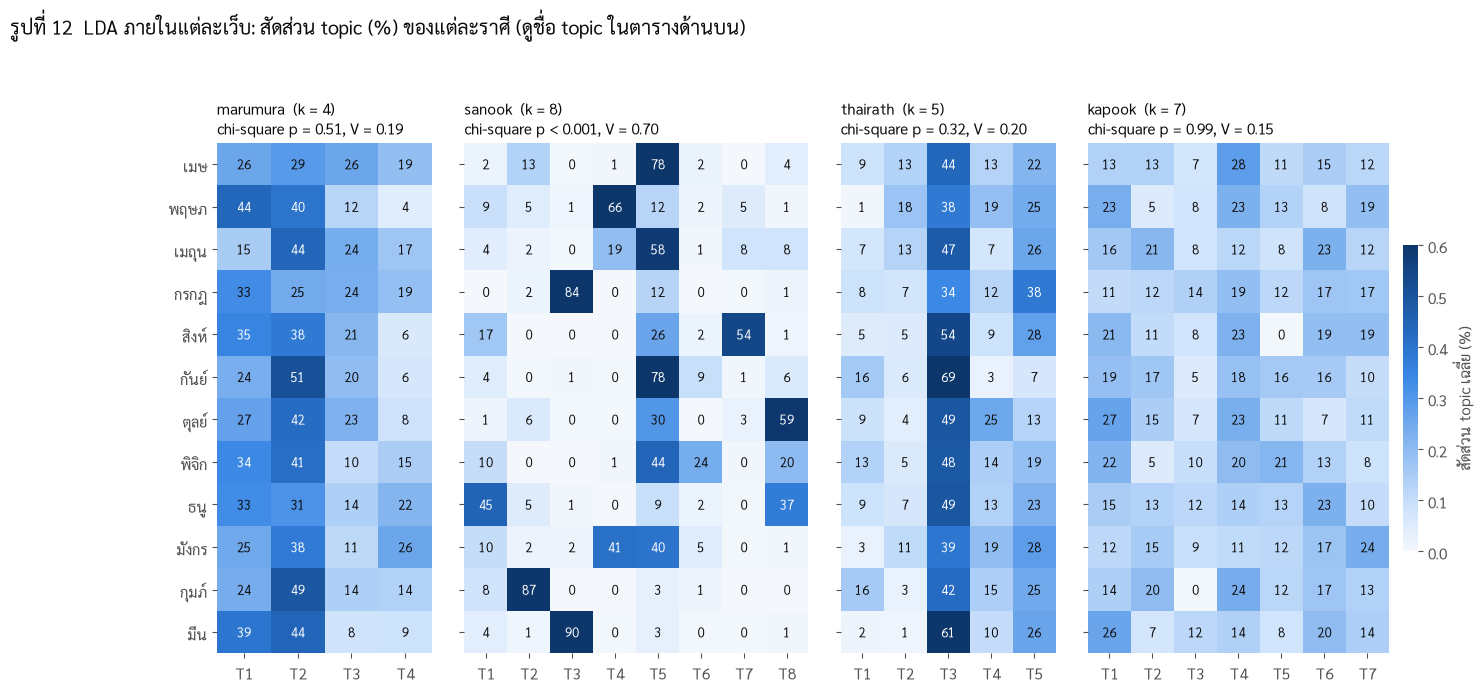

In [11]:
# Figure 12: topic share by sign, one panel per site
fig, axes = plt.subplots(1, len(SITES), figsize=(18, 7.4), gridspec_kw={"width_ratios": [max(int(best_k[s]), 5) for s in SITES]})
fig.subplots_adjust(top=0.80, wspace=0.12)
for ax, site in zip(axes, SITES):
    m = site_models[site]
    share = (pd.DataFrame(m["theta"], columns=[f"T{t + 1}" for t in range(int(best_k[site]))])
             .groupby(m["data"]["zodiac"]).mean().reindex(SIGNS))
    im = ax.imshow(share.values, cmap=BLUE_RAMP, vmin=0, vmax=0.6, aspect="auto")
    ax.set_xticks(range(share.shape[1]), share.columns)
    ax.set_yticks(range(12), [SIGN_TH[z] for z in SIGNS] if site == SITES[0] else [""] * 12)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in range(12):
        for j in range(share.shape[1]):
            v = share.values[i, j]
            ax.text(j, i, f"{v * 100:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.33 else "#0b0b0b")
    p = sign_tests.loc[site, "p_value"]
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.2f}"
    ax.set_title(f"{site}  (k = {int(best_k[site])})\nchi-square {p_text}, V = {sign_tests.loc[site, 'cramers_v']:.2f}",
                 loc="left", fontsize=11)
cbar = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.01)
cbar.set_label("สัดส่วน topic เฉลี่ย (%)")
cbar.outline.set_visible(False)
fig.suptitle("รูปที่ 12  LDA ภายในแต่ละเว็บ: สัดส่วน topic (%) ของแต่ละราศี (ดูชื่อ topic ในตารางด้านบน)",
             x=0.01, ha="left", fontsize=14)
fig.savefig(FIG_DIR / "04_topic_share_by_sign.png")
plt.show()

**จากตารางทดสอบและรูปที่ 12 พบว่า** (chi-square test ของตาราง ราศี × topic หลักของแต่ละข้อความ, Cramér's V วัดความเกี่ยวข้อง 0–1)
- **marumura (p = 0.51, V = 0.19), thairath (p = 0.32, V = 0.20), kapook (p = 0.99, V = 0.15):** สัดส่วน topic **ไม่ต่างกันตามราศี** ในรูปที่ 12 ทุกแถว (ราศี) ของ 3 เว็บนี้มีสีกระจายคล้ายๆ กัน
- **sanook (p < 0.001, V = 0.70):** สัดส่วน topic **ขึ้นกับราศีมาก** แต่ละราศีมี topic ดาวของตัวเอง เช่น ราศีมีน 90% และราศีกรกฎ 84% อยู่ใน T3 (ดาวเสาร์), ราศีกุมภ์ 87% อยู่ใน T2 (ดาวเสาร์–ราหู), ราศีสิงห์ 54% อยู่ใน T7 (ดาวอาทิตย์ ซึ่งเป็นดาวเจ้าเรือนของราศีสิงห์)
  เมื่อใช้ `text_strict` (ตัดส่วน "คำแนะนำ") ความเกี่ยวข้องลดจาก V = 0.70 เหลือ **0.38** แต่ยังมีนัยสำคัญ (p < 0.001) เพราะยังมีส่วน "สุขภาพ" ที่ใช้ซ้ำอยู่ (ดูโน้ตบุ๊ก 03)

*ข้อควรระวัง:* ตาราง 12 ราศี × k topic มีบางช่องที่ค่าคาดหวังน้อยกว่า 5 ซึ่งทำให้ chi-square test ไม่แม่นนัก แต่ผลไปทางเดียวกับโน้ตบุ๊ก 02 และ 03

## ส่วน C: BERTopic (L10)

BERTopic ต่างจาก LDA ตรงที่ไม่ได้นับคำ แต่ใช้**ความหมาย**ของข้อความ ทำงาน 4 ขั้น:
1. **Embedding:** แปลงแต่ละข้อความเป็นเวกเตอร์ความหมาย 384 มิติ ด้วยโมเดล `paraphrase-multilingual-MiniLM-L12-v2` (รองรับภาษาไทย)
2. **UMAP:** ลดมิติเหลือ 5 มิติ
3. **HDBSCAN:** จัดกลุ่ม (cluster) โดยไม่ต้องกำหนดจำนวน topic เอง ข้อความที่ไม่เข้ากลุ่มไหนจะเป็น topic −1 (outlier)
4. **c-TF-IDF:** หาคำที่เด่นของแต่ละกลุ่มเพื่อตั้งชื่อ topic (ใช้ตัวตัดคำ `topic_tokens` เดียวกับส่วน A และ B)

**ข้อควรระวัง:** โมเดล embedding อ่านได้แค่ **128 token** แต่ข้อความของ sanook ยาวประมาณ 400 token ถ้าใส่ทั้งข้อความโมเดลจะเห็นแค่ต้นข้อความ
จึง**แบ่งข้อความเป็นช่วงสั้นๆ (≤ 120 token) → embed ทีละช่วง → เฉลี่ย** ให้เวกเตอร์แทนทั้งข้อความ
การ embed ใช้เวลาประมาณ 9 นาทีบน CPU ผลจึงบันทึกไว้ที่ `outputs/04_embeddings.npy`

In [12]:
from bertopic import BERTopic
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_rand_score
from umap import UMAP

embedder = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2", device="cpu")

def chunks(text, max_tokens=120):
    """Split a text into pieces the model can read fully (it truncates after 128 tokens)."""
    pieces, current = [], ""
    for word_group in clean_text(text).split():          # Thai text: spaces separate phrases
        candidate = (current + " " + word_group).strip()
        if current and len(embedder.tokenizer(candidate)["input_ids"]) > max_tokens:
            pieces.append(current)
            current = word_group
        else:
            current = candidate
    return pieces + ([current] if current else [])

emb_cache = CACHE_DIR / "04_embeddings.npy"
if emb_cache.exists() and not RECOMPUTE:
    embeddings = np.load(emb_cache)
else:
    text_chunks = [chunks(t) for t in df["text"]]
    flat = [c for cs in text_chunks for c in cs]
    chunk_emb = embedder.encode(flat, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    embeddings, start = [], 0
    for cs in text_chunks:                              # average the chunks of each text
        v = chunk_emb[start:start + len(cs)].mean(axis=0)
        embeddings.append(v / np.linalg.norm(v))
        start += len(cs)
    embeddings = np.array(embeddings)
    np.save(emb_cache, embeddings)
print("embeddings:", embeddings.shape)

C:\Users\Jamvess\Downloads\horoscope-project\horoscope-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   6%|▌         | 12/199 [00:00<00:01, 110.63it/s]

Loading weights:  12%|█▏        | 24/199 [00:00<00:01, 113.61it/s]

Loading weights:  19%|█▉        | 38/199 [00:00<00:01, 121.45it/s]

Loading weights:  80%|███████▉  | 159/199 [00:00<00:00, 535.11it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 463.47it/s]

embeddings: (1233, 384)


In [13]:
def make_bertopic(min_cluster_size):
    return BERTopic(
        embedding_model=embedder,
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
        hdbscan_model=HDBSCAN(min_cluster_size=min_cluster_size, metric="euclidean",
                              cluster_selection_method="eom", prediction_data=True),
        # c-TF-IDF joins all texts of a topic into ONE document, so there are only a few documents: keep min_df=1
        vectorizer_model=CountVectorizer(tokenizer=topic_tokens, lowercase=False, token_pattern=None, min_df=1),
        top_n_words=10)

bt_all = make_bertopic(min_cluster_size=15)
bt_topics, _ = bt_all.fit_transform(df["text"].tolist(), embeddings=embeddings)
df["bertopic"] = bt_topics

# Adjusted Rand Index (L9): 1 = topics match the labels exactly, 0 = no better than random
kept = df["bertopic"] != -1
ari = pd.Series({"ARI(topic, เว็บ)": adjusted_rand_score(df.loc[kept, "source"], df.loc[kept, "bertopic"]),
                 "ARI(topic, ราศี)": adjusted_rand_score(df.loc[kept, "zodiac"], df.loc[kept, "bertopic"])})
print(f"{df['bertopic'].nunique() - (-1 in bt_topics)} topics, outliers (topic -1): {(~kept).mean():.0%}")
print(ari.round(3).to_string())

bt_table = pd.crosstab(df["bertopic"], df["source"]).reindex(columns=SITES, fill_value=0)
bt_table["n"] = bt_table.sum(axis=1)
bt_table["top words (c-TF-IDF)"] = [" ".join(w for w, _ in bt_all.get_topic(t)[:8]) for t in bt_table.index]
bt_table

4 topics, outliers (topic -1): 0%
ARI(topic, เว็บ)    0.648
ARI(topic, ราศี)   -0.002


source,marumura,sanook,thairath,kapook,n,top words (c-TF-IDF)
bertopic,,,,,,
0,311,0,1,312,624,คน อย่า ดี ระวัง มีเรื่อง ตัวเอง ปัญหา มีปัญหา
1,0,309,0,0,309,ควรระวัง ดาว อยู่ในเกณฑ์ ดี รัก เขต เป็นพิเศษ บ่งบอก
2,1,0,229,0,230,คู่ คน มีโอกาส เกณฑ์ เข้ามา งาน ดี มีปัญหา
3,0,0,70,0,70,ไก่ หมอ ทำบุญ แนะนำ เสริม ดวง คู่ คน


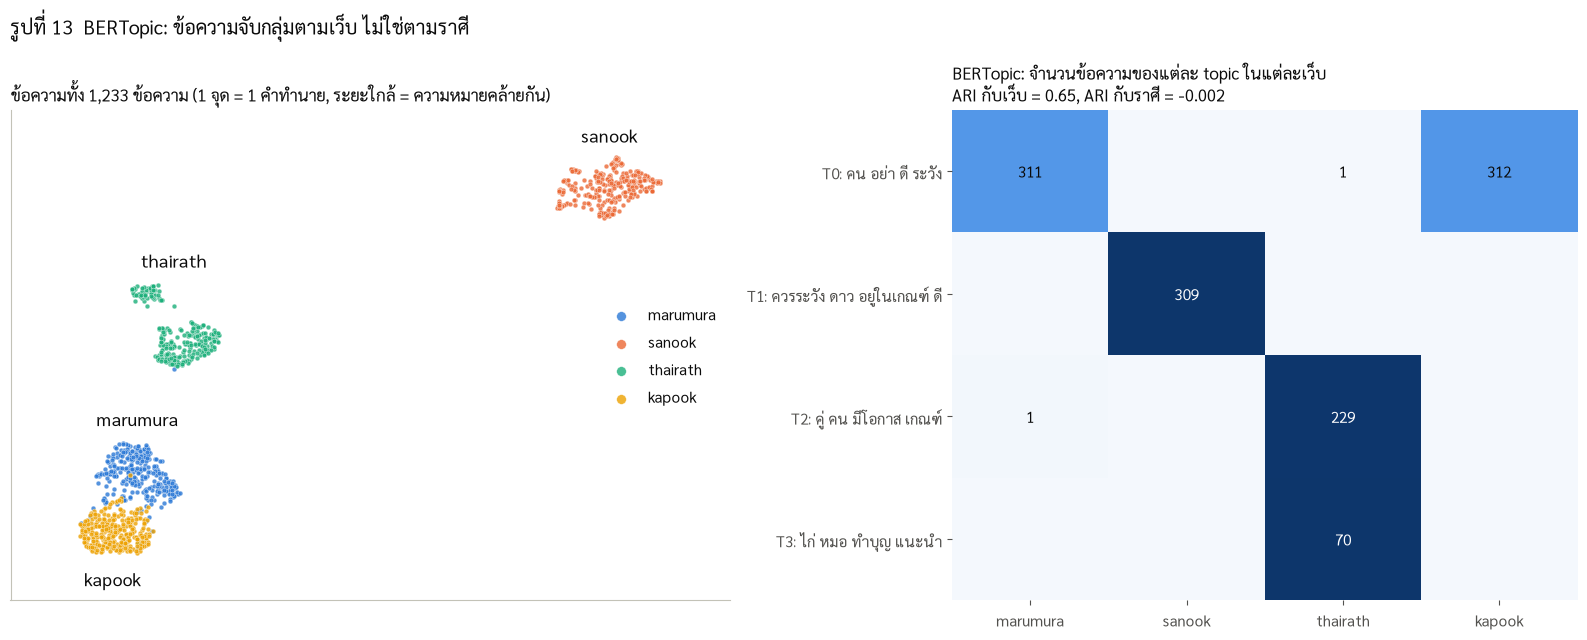

In [14]:
# Figure 13: left = every text as a point (2D UMAP of the embeddings), colored by site;
#            right = BERTopic topic x site counts
SITE_COLORS = {"marumura": "#2a78d6", "sanook": "#eb6834", "thairath": "#1baf7a", "kapook": "#eda100"}
xy = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=42).fit_transform(embeddings)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
for site in SITES:
    pts = xy[df["source"] == site]
    ax1.scatter(pts[:, 0], pts[:, 1], s=12, color=SITE_COLORS[site], alpha=0.8, linewidths=0.3,
                edgecolors="white", label=site)
pad = 0.04 * (xy[:, 1].max() - xy[:, 1].min())
LABEL_BELOW = {"kapook"}                # kapook's cloud touches marumura's from below -> label it underneath
for site in SITES:                      # direct label just outside each cloud
    pts = xy[df["source"] == site]
    lowest = site in LABEL_BELOW
    # 3rd / 97th percentile instead of min / max, so one stray point (e.g. 1 marumura text inside
    # the thairath cloud) does not move the label away from the main cloud
    y = np.percentile(pts[:, 1], 3) - pad if lowest else np.percentile(pts[:, 1], 97) + pad
    ax1.text(np.median(pts[:, 0]), y, site, fontsize=13, ha="center", va="top" if lowest else "bottom",
             color="#0b0b0b")
ax1.margins(0.12)
ax1.set_xticks([]); ax1.set_yticks([]); ax1.grid(False)
ax1.set_title("ข้อความทั้ง 1,233 ข้อความ (1 จุด = 1 คำทำนาย, ระยะใกล้ = ความหมายคล้ายกัน)", loc="left")
ax1.legend(frameon=False, loc="center right", markerscale=2)

counts = bt_table[SITES]
labels = [f"T{t}: " + " ".join(w for w, _ in bt_all.get_topic(t)[:4]) if t != -1 else "outlier" for t in counts.index]
share = counts.div(counts.sum(axis=1), axis=0)
ax2.imshow(share.values, cmap=BLUE_RAMP, vmin=0, vmax=1, aspect="auto")
ax2.set_xticks(range(len(SITES)), SITES)
ax2.set_yticks(range(len(labels)), labels)
ax2.grid(False)
for spine in ax2.spines.values():
    spine.set_visible(False)
for i in range(share.shape[0]):
    for j in range(len(SITES)):
        n = counts.values[i, j]
        if n:
            ax2.text(j, i, n, ha="center", va="center", fontsize=11, color="white" if share.values[i, j] > 0.55 else "#0b0b0b")
ax2.set_title(f"BERTopic: จำนวนข้อความของแต่ละ topic ในแต่ละเว็บ\nARI กับเว็บ = {ari.iloc[0]:.2f}, ARI กับราศี = {ari.iloc[1]:.3f}",
              loc="left")
fig.suptitle("รูปที่ 13  BERTopic: ข้อความจับกลุ่มตามเว็บ ไม่ใช่ตามราศี", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_bertopic.png")
plt.show()

**จากตารางและรูปที่ 13 พบว่า** BERTopic ซึ่งจัดกลุ่มตาม**ความหมาย** (ไม่ได้นับคำแบบ LDA) ก็แยกข้อความตาม**เว็บ**เช่นกัน
- **ภาพซ้าย:** เมื่อวางข้อความทั้ง 1,233 ข้อความตามความหมาย จะเห็น**กลุ่มก้อนแยกตามเว็บชัดเจน** sanook อยู่ไกลจากเว็บอื่นมาก thairath แยกเป็น 2 ก้อน ส่วน marumura กับ kapook อยู่ติดกัน
- **ภาพขวา:** BERTopic ได้ 4 topic (ไม่มี outlier) คือ T1 = sanook ทั้ง 309 ข้อความ, T2 = thairath ทั่วไป 229 ข้อความ, T3 = thairath ที่มี**คำแนะนำทำบุญเสริมดวงของหมอไก่** 70 ข้อความ และ T0 = marumura + kapook รวมกัน
- **Adjusted Rand Index (ARI, L9):** topic กับเว็บ = **0.65** แต่ topic กับราศี = **−0.002** ซึ่งเท่ากับการสุ่ม แปลว่าการรู้ topic ของข้อความ**ไม่ได้บอกอะไรเลย**ว่าเป็นราศีไหน

ผลนี้เป็นหลักฐานชิ้นที่ 4 และใช้วิธีที่ต่างจากเดิมโดยสิ้นเชิง (ความหมายจาก neural network แทนการนับคำ) แต่ได้ข้อสรุปเดียวกัน

In [15]:
# BERTopic inside each site (same idea as part B): do the clusters follow the sign?
rows = []
for site in SITES:
    idx = np.where(df["source"] == site)[0]
    model = make_bertopic(min_cluster_size=10)
    topics_site, _ = model.fit_transform(df["text"].iloc[idx].tolist(), embeddings=embeddings[idx])
    topics_site = np.array(topics_site)
    keep = topics_site != -1
    rows.append({"site": site, "topics": len(set(topics_site[keep])), "outliers": (~keep).mean(),
                 "ARI(topic, ราศี)": adjusted_rand_score(df["zodiac"].iloc[idx][keep], topics_site[keep]) if keep.sum() else np.nan,
                 "ตัวอย่าง topic": " | ".join(" ".join(w for w, _ in model.get_topic(t)[:5])
                                              for t in sorted(set(topics_site[keep]))[:3])})
pd.DataFrame(rows).set_index("site").round(3)

,topics,outliers,"ARI(topic, ราศี)",ตัวอย่าง topic
site,,,,
marumura,3,0.330,-0.007,คน อย่า ดี รัก เงิน | อย่า รอ ดี คน เจอ | คน ดี เดินทาง อย่า ดู
sanook,8,0.091,0.324,ควรระวัง ดี รัก อยู่ในเกณฑ์ ดาว | สร้าง มากขึ้น ตัวเอง ปล่อย ความทุกข์ | ดี ดาวเสาร์ อยู่ในเกณฑ์ มหาศาล งาน
thairath,2,0.000,-0.001,คน คู่ มีโอกาส ดี งาน | แนะนำ หมอ ไก่ ทำบุญ เสริม
kapook,6,0.542,0.014,ดี คน ระวัง งาน ปัญหา | คน ดี สถานการณ์ ตัวเอง มีปัญหา | ระวัง คน ปัญหา งาน มีเรื่อง


**จากตาราง BERTopic ภายในแต่ละเว็บ พบว่า**
- **marumura (ARI = −0.007), thairath (−0.001), kapook (0.014):** กลุ่มที่ BERTopic หาได้**ไม่เกี่ยวกับราศีเลย** (ARI ≈ 0) topic ของ thairath แยกแค่ว่าข้อความ "มีคำแนะนำทำบุญ" หรือไม่
- **sanook (ARI = 0.32):** กลุ่มเกี่ยวกับราศีระดับปานกลาง เพราะมีกลุ่มที่เป็นย่อหน้าเรื่องดาวประจำราศี (เช่น "ดาวเสาร์ มหาศาล") ตรงกับส่วน B และโน้ตบุ๊ก 03
- kapook มี outlier สูง (54%) เพราะข้อความทุกอันคล้ายกันมากจน HDBSCAN แยกกลุ่มได้ยาก

## สรุปผล 04 Topic modeling (ตอบวัตถุประสงค์ข้อ 2)

1. **topic model ทั้ง 3 วิธีแยกข้อความตามเว็บ:** LDA 3 topics โดยเฉลี่ย 78% ของแต่ละ topic มาจากเว็บเดียว, LSA ได้ผลแบบเดียวกัน และ **BERTopic** ได้ ARI กับเว็บ 0.65 แต่กับราศีแค่ −0.002 (เท่ากับการสุ่ม) ซึ่งเป็นหลักฐานเพิ่มเติม (ต่อจาก 02 และ 03) ว่า**คนเขียนกำหนดเนื้อหามากกว่าราศี**
2. **หัวข้อหลักของดวงคือ งาน เงิน ความสัมพันธ์ และโอกาส/ปัญหา** ซึ่งอยู่ปนกันในทุกข้อความตามแม่แบบของแต่ละเว็บ ส่วนสุขภาพแทบไม่เป็น topic เลย
   จุดเน้นต่างกันตามเว็บ: sanook = ดาว, thairath = โชคลาภ/ทำบุญ, marumura = การใช้เงิน/สิ่งเก่ากลับมา, kapook = ปัญหาและความสัมพันธ์
3. **สัดส่วนหัวข้อไม่ต่างกันตามราศี** ใน marumura, thairath และ kapook (LDA: p = 0.32–0.99, BERTopic: ARI ≈ 0) มีแค่ sanook ที่ต่าง เพราะแต่ละราศีมีย่อหน้าเรื่องดาวประจำราศีของตัวเอง

**ข้อจำกัด:** ข้อความสั้น (เฉลี่ย 68 คำหลังตัด stopword) และแต่ละเว็บมีแค่ประมาณ 300 ข้อความ topic จึงไม่คมชัดนัก (c_v ≈ 0.3–0.5) การตั้งชื่อ topic จาก top words ก็เป็นการตีความของทีมเอง
BERTopic ใช้โมเดล embedding ที่อ่านได้ทีละ 128 token จึงต้องแบ่งข้อความเป็นช่วงแล้วเฉลี่ย ซึ่งอาจเสียรายละเอียดของลำดับเนื้อหาไปบ้าง
**topics over time (stretch goal):** ยังไม่ได้ทำ เพราะ topic ของทุกวิธีคือเว็บ การดู topic ตามเวลาจึงเท่ากับดูสัดส่วนเว็บตามเวลา ถ้าจะตอบคำถาม "ช่วงวันหวยหรือสิ้นเดือนพูดเรื่องเงินมากขึ้นไหม" ควรดูคำเรื่องเงิน/โชคตามสัปดาห์โดยตรง

**รูปที่บันทึกไว้:** `outputs/figures/04_coherence_all.png`, `04_topics_by_site_all.png`, `04_topic_share_by_sign.png`, `04_bertopic.png`